In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

from ultralytics import YOLO

# Project paths
PROJECT_ROOT = Path.home() / "UltraCNN"
DATASET_ROOT = PROJECT_ROOT / "data" / "kitti" / "stereo2012"

SPLIT = "training"
IMAGE_ID = "000000"

left_path = (
    DATASET_ROOT / "data_stereo_flow" / SPLIT
    / "colored_0" / f"{IMAGE_ID}_10.png"
)

right_path = (
    DATASET_ROOT / "data_stereo_flow" / SPLIT
    / "colored_1" / f"{IMAGE_ID}_10.png"
)

assert left_path.is_file(), f"Left image not found: {left_path}"
assert right_path.is_file(), f"Right image not found: {right_path}"

left_image = cv2.imread(str(left_path))
right_image = cv2.imread(str(right_path))

assert left_image is not None
assert right_image is not None
assert left_image.shape == right_image.shape

print("Image dimensions:", left_image.shape)

Image dimensions: (370, 1226, 3)


In [7]:
calib_root = (
    DATASET_ROOT.parent
    / "stereo2012" / "data_stereo_flow_calib"
)

print("Calibration directory:", calib_root)
print("Directory exists:", calib_root.exists())

for path in sorted(calib_root.rglob("*")):
    if path.is_file():
        print(path.relative_to(calib_root))

Calibration directory: /home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow_calib
Directory exists: True
testing/calib/000000.txt
testing/calib/000001.txt
testing/calib/000002.txt
testing/calib/000003.txt
testing/calib/000004.txt
testing/calib/000005.txt
testing/calib/000006.txt
testing/calib/000007.txt
testing/calib/000008.txt
testing/calib/000009.txt
testing/calib/000010.txt
testing/calib/000011.txt
testing/calib/000012.txt
testing/calib/000013.txt
testing/calib/000014.txt
testing/calib/000015.txt
testing/calib/000016.txt
testing/calib/000017.txt
testing/calib/000018.txt
testing/calib/000019.txt
testing/calib/000020.txt
testing/calib/000021.txt
testing/calib/000022.txt
testing/calib/000023.txt
testing/calib/000024.txt
testing/calib/000025.txt
testing/calib/000026.txt
testing/calib/000027.txt
testing/calib/000028.txt
testing/calib/000029.txt
testing/calib/000030.txt
testing/calib/000031.txt
testing/calib/000032.txt
testing/calib/000033.txt
testing/calib/000034.txt
testing/calib

In [2]:
model = YOLO("yolo11n.pt")

results = model.predict(
    source=str(left_path),
    imgsz=640,
    conf=0.20,
    device=0 if torch.cuda.is_available() else "cpu",
    verbose=False
)

result = results[0]

# Keep car detections for this experiment
car_detections = []

for box in result.boxes:
    class_id = int(box.cls[0])

    if model.names[class_id] != "car":
        continue

    x1, y1, x2, y2 = box.xyxy[0].tolist()

    car_detections.append({
        "bbox": (x1, y1, x2, y2),
        "confidence": float(box.conf[0])
    })

print("Car detections:", len(car_detections))

for detection in car_detections:
    print(detection)

Car detections: 1
{'bbox': (622.9746704101562, 184.28720092773438, 661.3866577148438, 199.93125915527344), 'confidence': 0.27288034558296204}


In [3]:
left_gray = cv2.cvtColor(left_image, cv2.COLOR_BGR2GRAY)
right_gray = cv2.cvtColor(right_image, cv2.COLOR_BGR2GRAY)

window_size = 5

stereo = cv2.StereoSGBM_create(
    minDisparity=0,
    numDisparities=128,
    blockSize=window_size,
    P1=8 * window_size**2,
    P2=32 * window_size**2,
    disp12MaxDiff=1,
    uniquenessRatio=10,
    speckleWindowSize=100,
    speckleRange=2,
    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
)

disparity_raw = stereo.compute(left_gray, right_gray)
disparity = disparity_raw.astype(np.float32) / 16.0

valid_disparity = np.isfinite(disparity) & (disparity > 0)

print(
    "Valid disparity coverage:",
    f"{100 * valid_disparity.mean():.2f}%"
)

Valid disparity coverage: 82.07%


In [4]:
focal_length = 707.091
baseline = 0.5379

focal_baseline = focal_length * baseline

height, width = disparity.shape

localization_results = []

for detection in car_detections:
    x1, y1, x2, y2 = detection["bbox"]

    # Clamp bounding box to image dimensions
    x1 = max(0, min(width, int(np.floor(x1))))
    x2 = max(0, min(width, int(np.ceil(x2))))
    y1 = max(0, min(height, int(np.floor(y1))))
    y2 = max(0, min(height, int(np.ceil(y2))))

    if x2 <= x1 or y2 <= y1:
        continue

    # Extract disparity within the bounding box
    roi = disparity[y1:y2, x1:x2]
    roi_valid = np.isfinite(roi) & (roi > 0)

    if roi_valid.sum() < 10:
        print("Insufficient valid disparity for this car.")
        continue

    # Use the central region to reduce background contamination
    box_width = x2 - x1
    box_height = y2 - y1

    cx1 = x1 + int(0.20 * box_width)
    cx2 = x2 - int(0.20 * box_width)
    cy1 = y1 + int(0.20 * box_height)
    cy2 = y2 - int(0.20 * box_height)

    central_roi = disparity[cy1:cy2, cx1:cx2]

    central_valid = (
        np.isfinite(central_roi)
        & (central_roi > 0)
    )

    if central_valid.sum() >= 5:
        selected_disparities = central_roi[central_valid]
    else:
        selected_disparities = roi[roi_valid]

    median_disparity = float(np.median(selected_disparities))

    estimated_depth = focal_baseline / median_disparity

    # Approximate object location using the bounding-box center
    u = (x1 + x2) / 2.0
    v = (y1 + y2) / 2.0

    # Camera-frame coordinates using the image center as an
    # approximate principal point for this initial experiment.
    # We'll replace this with the calibrated principal point.
    cx = width / 2.0
    cy = height / 2.0

    X = (u - cx) * estimated_depth / focal_length
    Y = (v - cy) * estimated_depth / focal_length
    Z = estimated_depth

    localization_results.append({
        "bbox": (x1, y1, x2, y2),
        "confidence": detection["confidence"],
        "median_disparity": median_disparity,
        "valid_disparity_pixels": int(len(selected_disparities)),
        "X_m": X,
        "Y_m": Y,
        "Z_m": Z
    })

for item in localization_results:
    print("\nCar localization")
    for key, value in item.items():
        print(f"{key}: {value}")


Car localization
bbox: (622, 184, 662, 200)
confidence: 0.27288034558296204
median_disparity: 8.0625
valid_disparity_pixels: 240
X_m: 1.934772093023256
Y_m: 0.46701395348837216
Z_m: 47.174480483720934


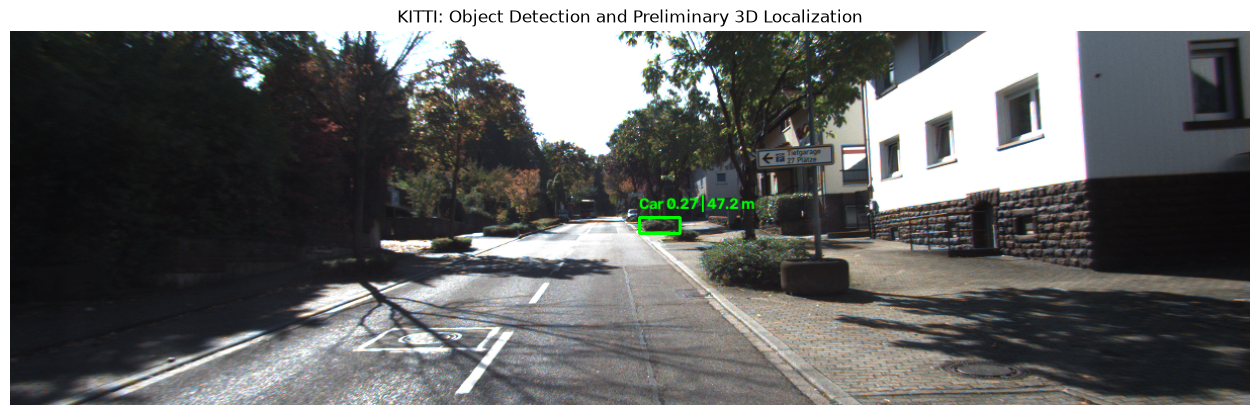

In [5]:
annotated = left_image.copy()

for item in localization_results:
    x1, y1, x2, y2 = item["bbox"]

    confidence = item["confidence"]
    distance = item["Z_m"]

    cv2.rectangle(
        annotated,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    label = f"Car {confidence:.2f} | {distance:.1f} m"

    cv2.putText(
        annotated,
        label,
        (x1, max(20, y1 - 8)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(16, 6))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title("KITTI: Object Detection and Preliminary 3D Localization")
plt.axis("off")
plt.show()